# 08. Statistical Significance Testing (RQ1-3)

This notebook evaluates the statistical significance of token fertility reductions achieved by **GhanaTok** (Byte-Level BPE & SentencePiece Unigram) compared against general multilingual baselines (**mBERT**, **XLM-R / AfroXLMR**) and regional baselines (**ABENA**) on held-out test sets (608 Twi sentences, 347 Ewe sentences).

### Methodology
1. **Paired Comparisons (RQ2)**: Every tokenizer is benchmarked on identical sentences in identical order. We use the non-parametric **Wilcoxon signed-rank test** for p-values and **1,000-iteration paired bootstrap** for 95% confidence intervals on absolute differences and percentage fertility reductions.
2. **Multiple Comparisons Correction**: **Holm-Bonferroni step-down correction** is applied across the primary family of 5 comparisons.
3. **Cross-Language Comparison (RQ3)**: Independent sample comparison (Twi vs. Ewe) using the **Mann-Whitney U test** and unpaired bootstrap confidence intervals.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure repo root is on sys.path
sys.path.insert(0, str(Path.cwd().parent))
from src.significance import (
    get_paired_fertility,
    paired_wilcoxon_test,
    paired_bootstrap_ci,
    unpaired_bootstrap_ci,
    apply_holm_bonferroni
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

## 1. Load Held-Out Benchmark Results

In [2]:
results_path = Path("../reports/tables/final_heldout_results.csv")
df = pd.read_csv(results_path)
print(f"Loaded {len(df)} sentence evaluation rows.")
df.head()

Loaded 5383 sentence evaluation rows.


,n_words,n_chars,n_tokens,tokens_per_word,tokens_per_char,pct_words_split,tokenizer,language
0,27,125,62,2.296296,0.496000,55.555556,mBERT,twi
1,57,331,142,2.491228,0.429003,77.192982,mBERT,twi
2,36,175,75,2.083333,0.428571,61.111111,mBERT,twi
3,14,74,44,3.142857,0.594595,85.714286,mBERT,twi
4,19,87,46,2.421053,0.528736,63.157895,mBERT,twi


## 2. RQ2 Significance Results (Primary & Bonus Comparisons)

In [3]:
rq2_table_path = Path("../reports/tables/rq2_significance_results.csv")
rq2_df = pd.read_csv(rq2_table_path)
rq2_df

,language,comparison_tier,tokenizer_a,tokenizer_b,n_sentences,mean_fertility_a,mean_fertility_b,mean_diff,diff_ci_95,pct_reduction,pct_ci_95,wilcoxon_stat,wilcoxon_p,p_holm_corrected,significant_corrected
0,twi,Primary (BPE),GhanaTok,mBERT,608,1.656,2.389,-0.7326,"[-0.7566, -0.7084]",30.67,"[29.85%, 31.44%]",514.5,2.481955e-99,7.445866e-99,True
1,twi,Primary (BPE),GhanaTok,XLM-R,608,1.656,2.444,-0.7877,"[-0.8122, -0.7622]",32.23,"[31.45%, 32.98%]",324.0,2.119955e-100,1.059978e-99,True
2,twi,Primary (BPE),GhanaTok,ABENA,608,1.656,2.419,-0.7631,"[-0.7868, -0.7377]",31.54,"[30.72%, 32.30%]",465.0,9.082023e-100,3.632809e-99,True
3,ewe,Primary (BPE),GhanaTok,mBERT,347,1.750,2.291,-0.5407,"[-0.5811, -0.4989]",23.60,"[22.08%, 24.95%]",1521.0,2.483655e-52,2.483655e-52,True
4,ewe,Primary (BPE),GhanaTok,XLM-R,347,1.750,2.608,-0.8582,"[-0.9017, -0.8148]",32.90,"[31.61%, 34.11%]",463.0,9.899974e-57,1.979995e-56,True
5,twi,Bonus (Unigram),GhanaTok-Unigram,mBERT,608,1.251,2.389,-1.1377,"[-1.1682, -1.1109]",47.63,"[46.81%, 48.43%]",35.0,3.491641e-101,2.249646e-100,True
6,twi,Bonus (Unigram),GhanaTok-Unigram,XLM-R,608,1.251,2.444,-1.1928,"[-1.2226, -1.1654]",48.81,"[48.02%, 49.62%]",18.0,3.213780e-101,2.249646e-100,True
7,twi,Bonus (Unigram),GhanaTok-Unigram,ABENA,608,1.251,2.419,-1.1682,"[-1.1991, -1.1404]",48.29,"[47.48%, 49.08%]",29.0,3.385654e-101,2.249646e-100,True
8,twi,Bonus (Unigram),GhanaTok-Unigram,GhanaTok,608,1.251,1.656,-0.4051,"[-0.4193, -0.3912]",24.46,"[23.71%, 25.23%]",52.5,7.088572e-99,2.835429e-98,True
9,ewe,Bonus (Unigram),GhanaTok-Unigram,mBERT,347,1.349,2.291,-0.9416,"[-0.9835, -0.8978]",41.11,"[39.67%, 42.39%]",462.5,9.843104e-57,9.843104e-57,True


## 3. RQ3 Unpaired Cross-Language Comparison (Twi vs Ewe)

In [4]:
rq3_table_path = Path("../reports/tables/rq3_significance_results.csv")
rq3_df = pd.read_csv(rq3_table_path)
rq3_df

,tokenizer,twi_n,twi_mean_fertility,ewe_n,ewe_mean_fertility,mean_diff_twi_minus_ewe,diff_ci_95,mann_whitney_u,mann_whitney_p,significant_at_05
0,GhanaTok,608,1.656,347,1.750,-0.0937,"[-0.1278, -0.0610]",79394.5,1.938019e-10,True
1,GhanaTok-Unigram,608,1.251,347,1.349,-0.0979,"[-0.1306, -0.0668]",74567.5,4.584395e-14,True


## 4. Visualizing Paired Differences and Bootstrap Distributions

<cell_9_expr>:23: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


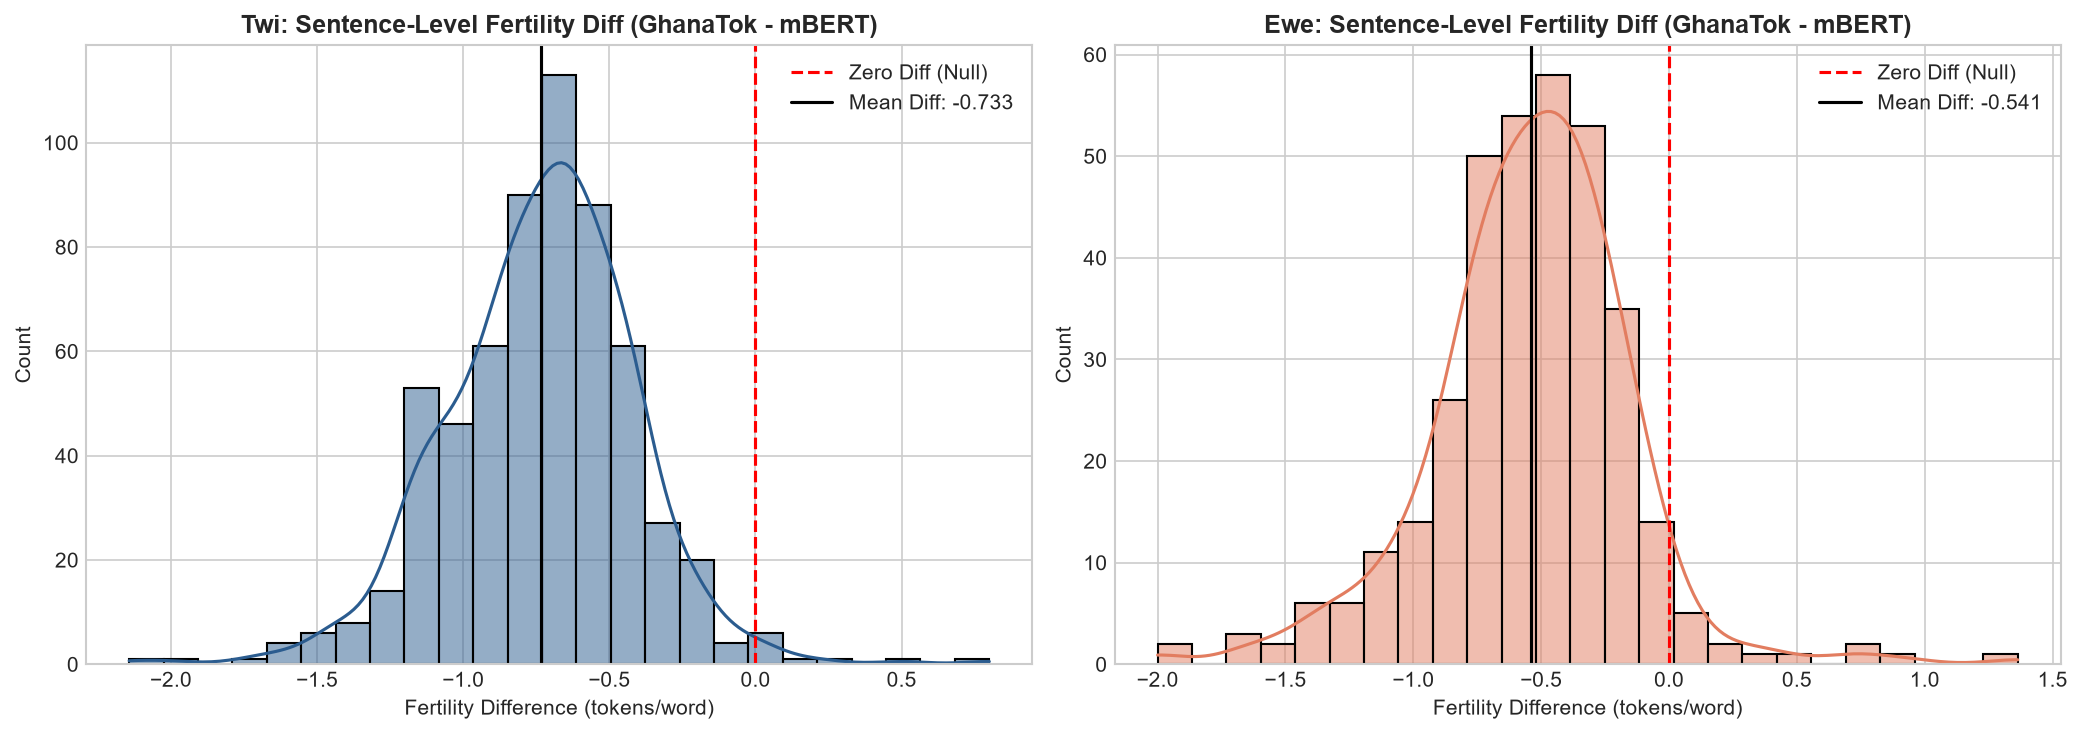

In [5]:
twi_ghana, twi_mbert = get_paired_fertility(df, "twi", "GhanaTok", "mBERT")
ewe_ghana, ewe_mbert = get_paired_fertility(df, "ewe", "GhanaTok", "mBERT")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Twi differences
sns.histplot(twi_ghana - twi_mbert, kde=True, ax=axes[0], color="#2b5c8f", bins=25)
axes[0].axvline(0, color="red", linestyle="--", label="Zero Diff (Null)")
axes[0].axvline((twi_ghana - twi_mbert).mean(), color="black", linestyle="-", label=f"Mean Diff: {(twi_ghana - twi_mbert).mean():.3f}")
axes[0].set_title("Twi: Sentence-Level Fertility Diff (GhanaTok - mBERT)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Fertility Difference (tokens/word)")
axes[0].legend()

# Ewe differences
sns.histplot(ewe_ghana - ewe_mbert, kde=True, ax=axes[1], color="#e27d60", bins=25)
axes[1].axvline(0, color="red", linestyle="--", label="Zero Diff (Null)")
axes[1].axvline((ewe_ghana - ewe_mbert).mean(), color="black", linestyle="-", label=f"Mean Diff: {(ewe_ghana - ewe_mbert).mean():.3f}")
axes[1].set_title("Ewe: Sentence-Level Fertility Diff (GhanaTok - mBERT)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Fertility Difference (tokens/word)")
axes[1].legend()

plt.tight_layout()
plt.show()